# 03 — Modèle 1 : CNN baseline

**Objectif :** établir un point de référence simple. Tous les modèles suivants devront faire mieux que lui
sur le **même** split de test (split par série, voir notebook 02).

**Modèle** (`src/model1.py`) : CNN entraîné from scratch.
- 4 blocs `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2` (32 → 64 → 128 → 256 canaux)
- `Global Average Pooling → Dropout 0.3 → Linear(256, 4)`
- ~390 k paramètres, entrée 1×128×128

**Entraînement** (`train.py`) : AdamW, OneCycleLR, CrossEntropy pondérée par l'inverse de la fréquence des
classes, flip horizontal. Pas de calcul en fp16 : sur GTX 16xx il produit des NaN.

> Pour créer un nouveau modèle : dupliquer ce notebook en `04_model2_<nom>.ipynb`, créer `src/model2.py`,
> l'enregistrer dans `src/__init__.py`, et créer `configs/model2.yaml`.

In [1]:
import os, sys
from pathlib import Path

# Le notebook tourne depuis notebooks/ : on se place à la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image

from src import get_model
from src.data import CLASSES, DATA_DIR, list_split_files, load_split
from src.viz import setup_style, plot_curves, plot_confusion, CLASS_COLORS, INK_MUTED
from train import train
from eval import evaluate, predict

setup_style()
CONFIG = "configs/model1.yaml"
print("GPU :", torch.cuda.get_device_name(0))

GPU : NVIDIA GeForce GTX 1650


## 1. Configuration

In [2]:
cfg = yaml.safe_load(Path(CONFIG).read_text())
print(yaml.safe_dump(cfg, sort_keys=False))

model:
  name: model1
  params:
    dropout: 0.3
data:
  img_size: 128
train:
  epochs: 10
  batch_size: 64
  lr: 0.001
  weight_decay: 0.0001
  class_weights: true
seed: 42



## 2. Architecture

In [ ]:
model = get_model(
    cfg["model"]["name"], n_classes=len(CLASSES), **cfg["model"].get("params", {})
)
print(model)
pd.DataFrame(
    [
        {"bloc": n, "paramètres": sum(p.numel() for p in m.parameters())}
        for n, m in list(model.features.named_children()) + [("head", model.head)]
    ]
).set_index("bloc").assign(total=lambda d: d["paramètres"].sum())

Model1(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0

,paramètres,total
bloc,,
0,352,389348
1,18560,389348
2,73984,389348
3,295424,389348
head,1028,389348


## 3. Données
Splits produits par le notebook 02 (déjà prétraités et en cache).

In [ ]:
for s in ["train", "valid", "test"]:
    X, y = load_split(s, cfg["data"]["img_size"])
    print(
        f"{s:5s}: {X.shape}  "
        + "  ".join(f"{c}={n}" for c, n in zip(CLASSES, np.bincount(y)))
    )

train: (8166, 128, 128)  Cyst=2259  Normal=3443  Stone=938  Tumor=1526
valid: (1788, 128, 128)  Cyst=512  Normal=686  Stone=197  Tumor=393
test : (1975, 128, 128)  Cyst=513  Normal=873  Stone=225  Tumor=364


## 4. Entraînement

`train()` crée un nouveau dossier `results/model1-vN/` à chaque appel (les anciens runs ne sont jamais écrasés).
Pour **recharger un run existant sans réentraîner**, mettre son chemin dans `RUN_DIR`.

In [ ]:
RUN_DIR = None  # ex. "results/model1-v1" pour recharger un run sans réentraîner

run_dir = Path(RUN_DIR) if RUN_DIR else train(CONFIG)
print("Run :", run_dir)

Run : results/model1-v3  |  GPU : NVIDIA GeForce GTX 1650
Paramètres : 389,348
Epoch  1/10 | train loss 0.9961 acc 0.6140 | val loss 1.1679 acc 0.4855 | 25.2s
Epoch  2/10 | train loss 0.5613 acc 0.8218 | val loss 1.7301 acc 0.4715 | 10.7s
Epoch  3/10 | train loss 0.2887 acc 0.9166 | val loss 2.4514 acc 0.2438 | 10.3s
Epoch  4/10 | train loss 0.1429 acc 0.9650 | val loss 2.1198 acc 0.5447 | 10.3s
Epoch  5/10 | train loss 0.0750 acc 0.9854 | val loss 1.7365 acc 0.6096 | 10.3s
Epoch  6/10 | train loss 0.0348 acc 0.9951 | val loss 2.7981 acc 0.5213 | 10.3s
Epoch  7/10 | train loss 0.0125 acc 0.9994 | val loss 1.7404 acc 0.5240 | 10.4s
Epoch  8/10 | train loss 0.0080 acc 0.9998 | val loss 1.6549 acc 0.6622 | 10.4s
Epoch  9/10 | train loss 0.0059 acc 0.9999 | val loss 1.6922 acc 0.6270 | 10.4s
Epoch 10/10 | train loss 0.0053 acc 1.0000 | val loss 1.7436 acc 0.6527 | 10.4s
Meilleure val acc : 0.6622
Run : results/model1-v3


## 5. Courbes d'apprentissage

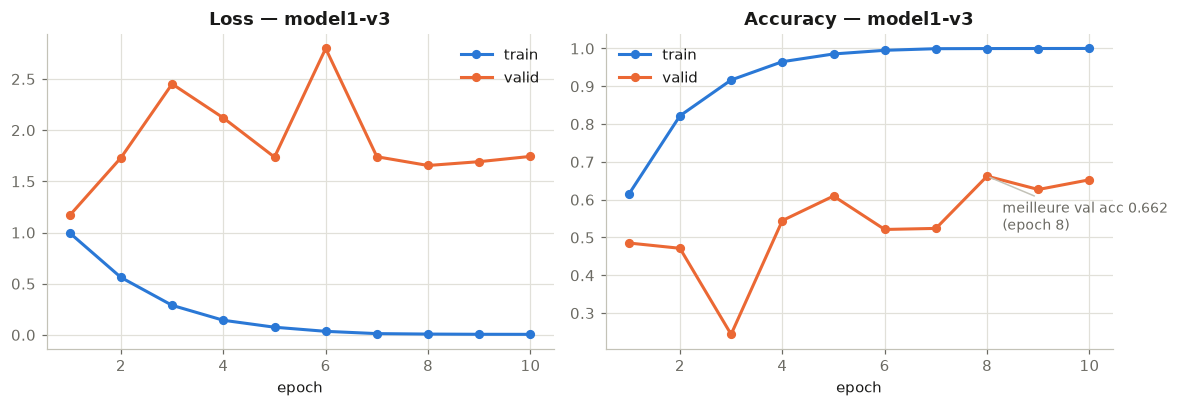

In [ ]:
plot_curves(run_dir)
plt.show()

## 6. Évaluation sur le test
Le meilleur modèle (meilleure accuracy de validation) est évalué sur le split test, résultat dans `test_output.json`.

In [7]:
out = evaluate(run_dir)

=== TEST — model1-v3 (best.pt) ===
              precision    recall  f1-score   support

        Cyst     0.7827    0.9903    0.8744       513
      Normal     0.8032    0.9771    0.8817       873
       Stone     0.7008    0.7600    0.7292       225
       Tumor     0.7000    0.0385    0.0729       364

    accuracy                         0.7828      1975
   macro avg     0.7467    0.6915    0.6395      1975
weighted avg     0.7672    0.7828    0.7133      1975

Matrice de confusion (lignes = vrai, colonnes = prédit) :
[[508   0   5   0]
 [  0 853  14   6]
 [ 47   7 171   0]
 [ 94 202  54  14]]
-> results/model1-v3/test_output.json


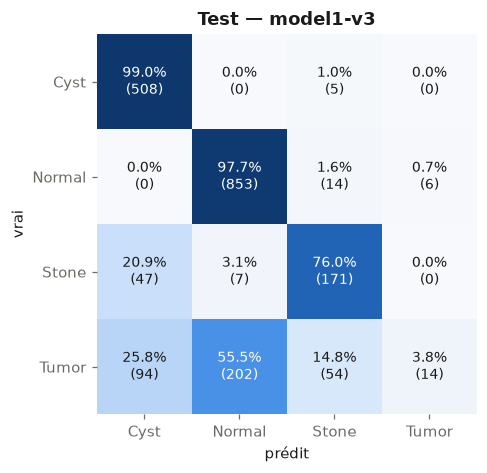

,precision,recall,f1-score,support
Cyst,0.783,0.990,0.874,513.0
Normal,0.803,0.977,0.882,873.0
Stone,0.701,0.760,0.729,225.0
Tumor,0.700,0.038,0.073,364.0


In [ ]:
plot_confusion(out["confusion_matrix"]["matrix"], CLASSES, f"Test — {run_dir.name}")
plt.show()
pd.DataFrame(out["per_class"]).T.round(3)

## 7. Analyse des erreurs
### Performance par type de coupe

In [ ]:
y, p, probs = predict(run_dir)
files = list_split_files("test")
meta = pd.read_csv(DATA_DIR / "metadata.csv").set_index(["cls", "filename"])
res = pd.DataFrame(
    {
        "filename": [f.name for f, _ in files],
        "cls": [CLASSES[l] for _, l in files],
        "pred": [CLASSES[i] for i in p],
        "conf": probs.max(1),
        "correct": y == p,
    }
)
res = res.join(meta[["view", "series"]], on=["cls", "filename"])
res.pivot_table(index="cls", columns="view", values="correct", aggfunc="mean").reindex(
    CLASSES
).round(3)

view,axial,coronal
cls,,
Cyst,1.00,0.891
Normal,1.00,0.955
Stone,0.85,0.400
Tumor,0.00,0.130


### Erreurs regroupées par série
Une série mal classée en entier signale un examen « difficile » ; des erreurs isolées sont plutôt du bruit.

In [ ]:
by_series = res.groupby("series").agg(
    cls=("cls", "first"),
    view=("view", "first"),
    n=("correct", "size"),
    accuracy=("correct", "mean"),
)
by_series.sort_values("accuracy").head(10).round(3)

,cls,view,n,accuracy
series,,,,
Stone_0171,Stone,axial,16,0.0
Stone_0174,Stone,coronal,11,0.0
Stone_0131,Stone,coronal,6,0.0
Stone_0156,Stone,axial,4,0.0
Stone_0137,Stone,coronal,4,0.0
Tumor_0206,Tumor,coronal,54,0.0
Stone_0177,Stone,coronal,6,0.0
Stone_0176,Stone,axial,6,0.0
Tumor_0203,Tumor,axial,202,0.0


### Exemples d'erreurs (les plus confiantes)

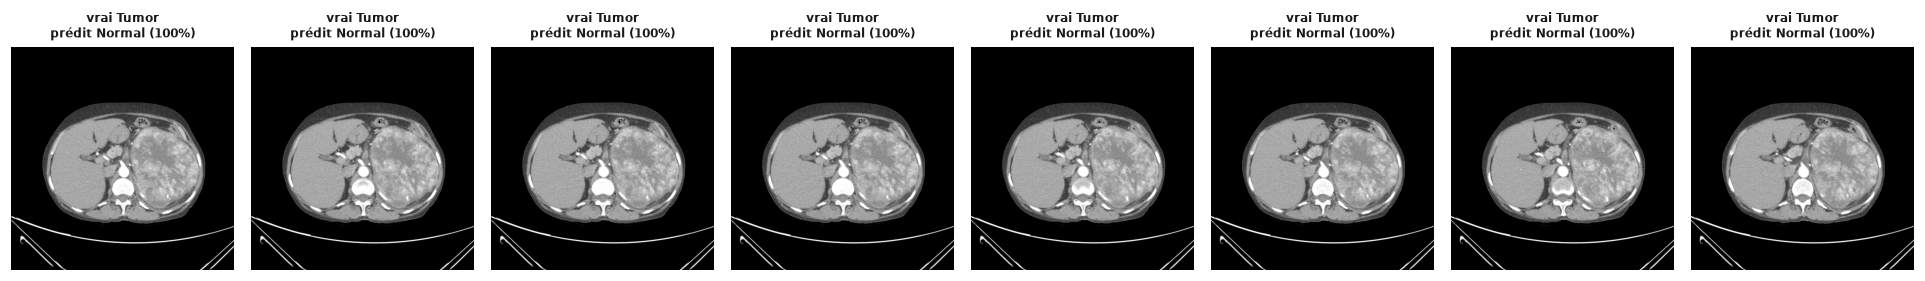

In [ ]:
errors = res[~res.correct].sort_values("conf", ascending=False).head(8)
if len(errors):
    fig, axes = plt.subplots(
        1, len(errors), figsize=(2.2 * len(errors), 2.8), squeeze=False
    )
    for ax, (_, r) in zip(axes[0], errors.iterrows()):
        ax.imshow(
            Image.open(DATA_DIR / "test" / r.cls / r.filename).convert("L"), cmap="gray"
        )
        ax.axis("off")
        ax.set_title(f"vrai {r.cls}\nprédit {r.pred} ({r.conf:.0%})", fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur sur le test.")

## 8. Conclusions

Run `model1-v1`, split par série. Les chiffres peuvent varier légèrement d'un run à l'autre.

**Résultats test :** accuracy **73,4 %**, F1 macro **0,53**. Avec l'ancien split aléatoire, le même modèle
affichait 99,9 % : l'écart mesure la fuite de données corrigée dans le notebook 02.

**Ce qu'on observe**
- **Sur-apprentissage massif :** 100 % en train dès l'epoch 7, alors que la loss de validation monte dès
  l'epoch 2. Le modèle mémorise les séries du train au lieu d'apprendre des caractéristiques des lésions.
- **Biais vers Normal et Cyst :** rappel de 100 % sur ces deux classes, mais **21 % sur Stone** et **4 % sur Tumor**.
  70 % des tumeurs sont classées Normal. La pondération de la loss ne suffit pas.
- **Erreurs par série entière** (ex. une série Tumor de 202 coupes entièrement ratée) : le problème est la
  généralisation à de **nouveaux examens**, pas quelques images ambiguës.
- **Validation instable** (0,25 → 0,68 d'une epoch à l'autre), car elle repose sur peu de séries (3 pour Tumor).

**Pistes pour les modèles suivants**
1. Régularisation et augmentation plus fortes (rotations, crops, variations de contraste), early stopping sur la val loss.
2. **Transfer learning** (ResNet18 / EfficientNet pré-entraînés sur ImageNet) : plus robuste avec peu de patients.
3. Résolution plus élevée (224 px ou plus) : les calculs ne font que quelques pixels à 128 px.
4. Évaluation par validation croisée par groupes (`StratifiedGroupKFold`) pour des comparaisons moins bruitées.